# Stamp, Batch и Witness

Этот выполненный notebook читает сохраненные результаты новой серии. Он не запускает измерения. [Отчет](report.pdf) и [протокол C++](../../cpp/mpgaa_lazy/README.md) описывают инварианты и ограничения. Stamp использует версии плиток, Batch выбирает способ начального ремонта при освобождениях, Witness хранит компактное сечение препятствий.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'cpp/mpgaa_lazy').is_dir())
AD = ROOT/'cpp/mpgaa_lazy/results/full/analysis'
checks = json.loads((AD/'analysis.json').read_text())
display({k:checks[k] for k in ['status','timed_runs','memory_runs','scenarios','timed_planner_calls','exact_cost_disagreements','capped_calls','independent_dijkstra_comparisons','memory_matched_rows']})
cases = pd.read_csv(AD/'case_metrics.csv')
summary = pd.read_csv(AD/'summary.csv')
new = ['stamp_mpgaa','batch_mpgaa','witness_mpgaa']

{'status': 'passed',
 'timed_runs': 10464,
 'memory_runs': 3488,
 'scenarios': 298,
 'timed_planner_calls': 307455,
 'exact_cost_disagreements': 0,
 'capped_calls': 6,
 'independent_dijkstra_comparisons': 7790,
 'memory_matched_rows': 102485}

## Полное время, online и полнота

Время — медиана трех повторов внутри конфигурации. В таблицах — геометрическое среднее парных отношений baseline / candidate. Больше 1 выгодно кандидату. Пары требуют завершения обоих методов; replay считает корректное отсутствие пути завершением, навигация требует достижения цели.

,cohort,control,method,episode_speedup,episode_speedup_lo,episode_speedup_hi,online_speedup,paired,configurations
57,replay,car16,stamp_mpgaa,1.292814,1.141563,1.598600,2.086527,90,90
58,navigation_dynamic,car16,stamp_mpgaa,1.158419,1.102201,1.201057,1.425842,16,24
59,navigation_unknown,car16,stamp_mpgaa,1.413932,1.158724,1.713637,2.186567,48,48
60,navigation_dynamic,grid8,stamp_mpgaa,1.014769,0.988860,1.042029,1.009049,39,40
61,replay,grid8,stamp_mpgaa,1.052221,1.036780,1.069120,1.059315,96,96
62,replay,car16,batch_mpgaa,1.311057,1.139225,1.697330,2.118495,90,90
63,navigation_dynamic,car16,batch_mpgaa,1.161710,1.074437,1.258756,1.424487,16,24
64,navigation_unknown,car16,batch_mpgaa,1.408568,1.143522,1.718422,2.205044,48,48
65,navigation_dynamic,grid8,batch_mpgaa,1.001808,0.965996,1.039281,0.997056,39,40
66,replay,grid8,batch_mpgaa,1.055651,1.029556,1.076396,1.060897,96,96


sum  size
cohort             control method                  
navigation_dynamic car16   batch_mpgaa     16    24
                           stamp_mpgaa     16    24
                           witness_mpgaa   16    24
                   grid8   batch_mpgaa     39    40
                           stamp_mpgaa     39    40
                           witness_mpgaa   39    40
navigation_unknown car16   batch_mpgaa     48    48
                           stamp_mpgaa     48    48
                           witness_mpgaa   48    48
replay             car16   batch_mpgaa     90    90
                           stamp_mpgaa     90    90
                           witness_mpgaa   90    90
                   grid8   batch_mpgaa     96    96
                           stamp_mpgaa     96    96
                           witness_mpgaa   96    96

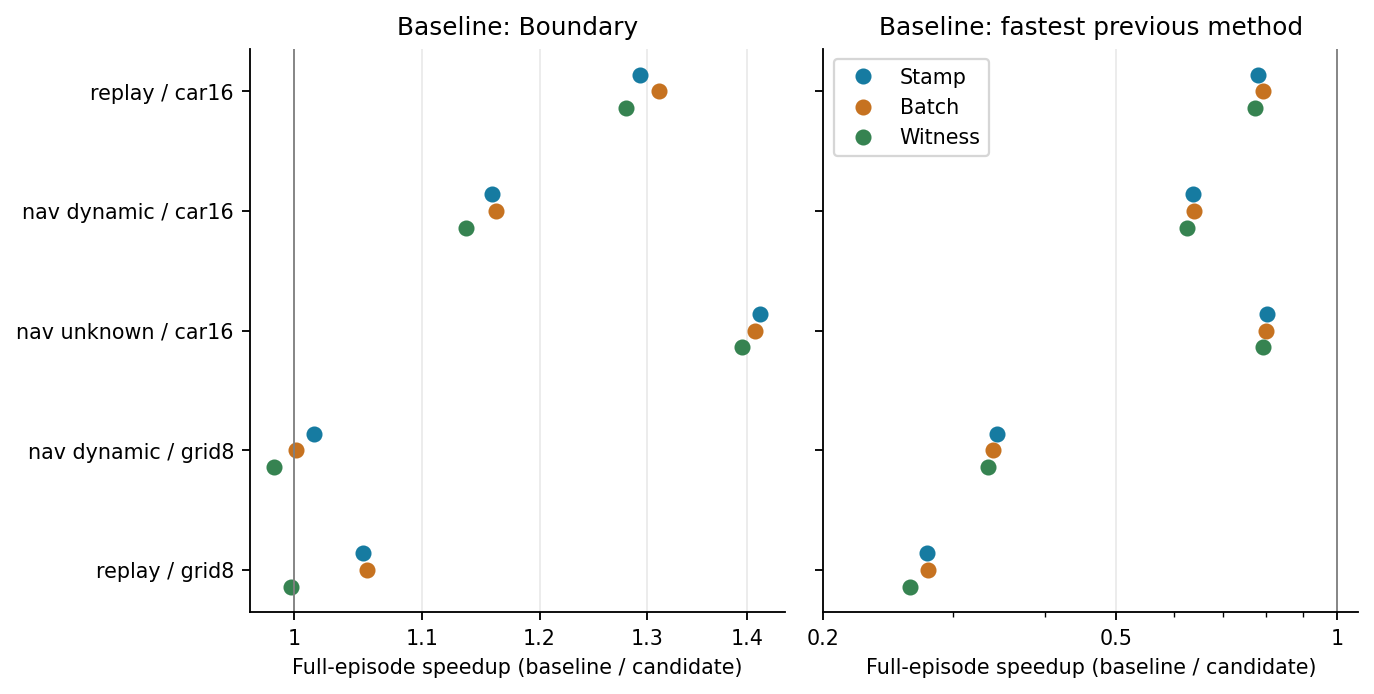

In [2]:
display(summary[summary.method.isin(new) & summary.baseline.eq('boundary_mpgaa')][['cohort','control','method','episode_speedup','episode_speedup_lo','episode_speedup_hi','online_speedup','paired','configurations']])
display(cases[cases.method.isin(new)].groupby(['cohort','control','method']).complete.agg(['sum','size']))
display(Image(filename=str(ROOT/'docs/mpgaa_lazy/figures/episode_speedup.png'), width=950))

## Карты, радиусы и сильные контроли

`best_control` выбирает самый быстрый завершившийся прежний метод по полному эпизоду после измерения. В closed-loop навигации методы исполняют собственные маршруты и могут получать разные наблюдения. Два корня и конфигурации одной карты не являются независимыми новыми картами.

,control,map,method,episode_speedup,online_speedup,paired,configurations
1162,car16,AR0700,stamp_mpgaa,0.818855,NaN,1,4
1165,car16,Berlin,stamp_mpgaa,0.776835,1.002622,2,4
1168,car16,MA_maze96,stamp_mpgaa,0.269679,0.029183,4,4
1171,car16,MA_random96,stamp_mpgaa,0.880021,0.830108,3,4
1174,car16,MA_room96,stamp_mpgaa,0.895143,1.145684,3,4
1177,car16,arena,stamp_mpgaa,0.834121,1.095578,3,4
1180,grid8,AR0700,stamp_mpgaa,0.534454,0.534463,3,4
1181,grid8,Berlin,stamp_mpgaa,0.575961,0.560494,4,4
1182,grid8,MA_maze512,stamp_mpgaa,0.273413,0.276720,4,4
1183,grid8,MA_random512,stamp_mpgaa,0.404781,0.396524,4,4


,control,map,k,cr,method,roots,paired,paired_online,min_episode_speedup,min_online_speedup
0,car16,AR0700,2,5,batch_mpgaa,2,0,0,NaN,NaN
1,car16,AR0700,2,5,stamp_mpgaa,2,0,0,NaN,NaN
2,car16,AR0700,2,5,witness_mpgaa,2,0,0,NaN,NaN
3,car16,AR0700,32,20,batch_mpgaa,2,1,0,0.801467,NaN
4,car16,AR0700,32,20,stamp_mpgaa,2,1,0,0.818855,NaN
...,...,...,...,...,...,...,...,...,...,...
91,grid8,random50_p40,2,5,stamp_mpgaa,2,2,2,0.424920,0.506896
92,grid8,random50_p40,2,5,witness_mpgaa,2,2,2,0.376528,0.470826
93,grid8,random50_p40,32,20,batch_mpgaa,2,2,2,0.219756,0.230096
94,grid8,random50_p40,32,20,stamp_mpgaa,2,2,2,0.219398,0.229887


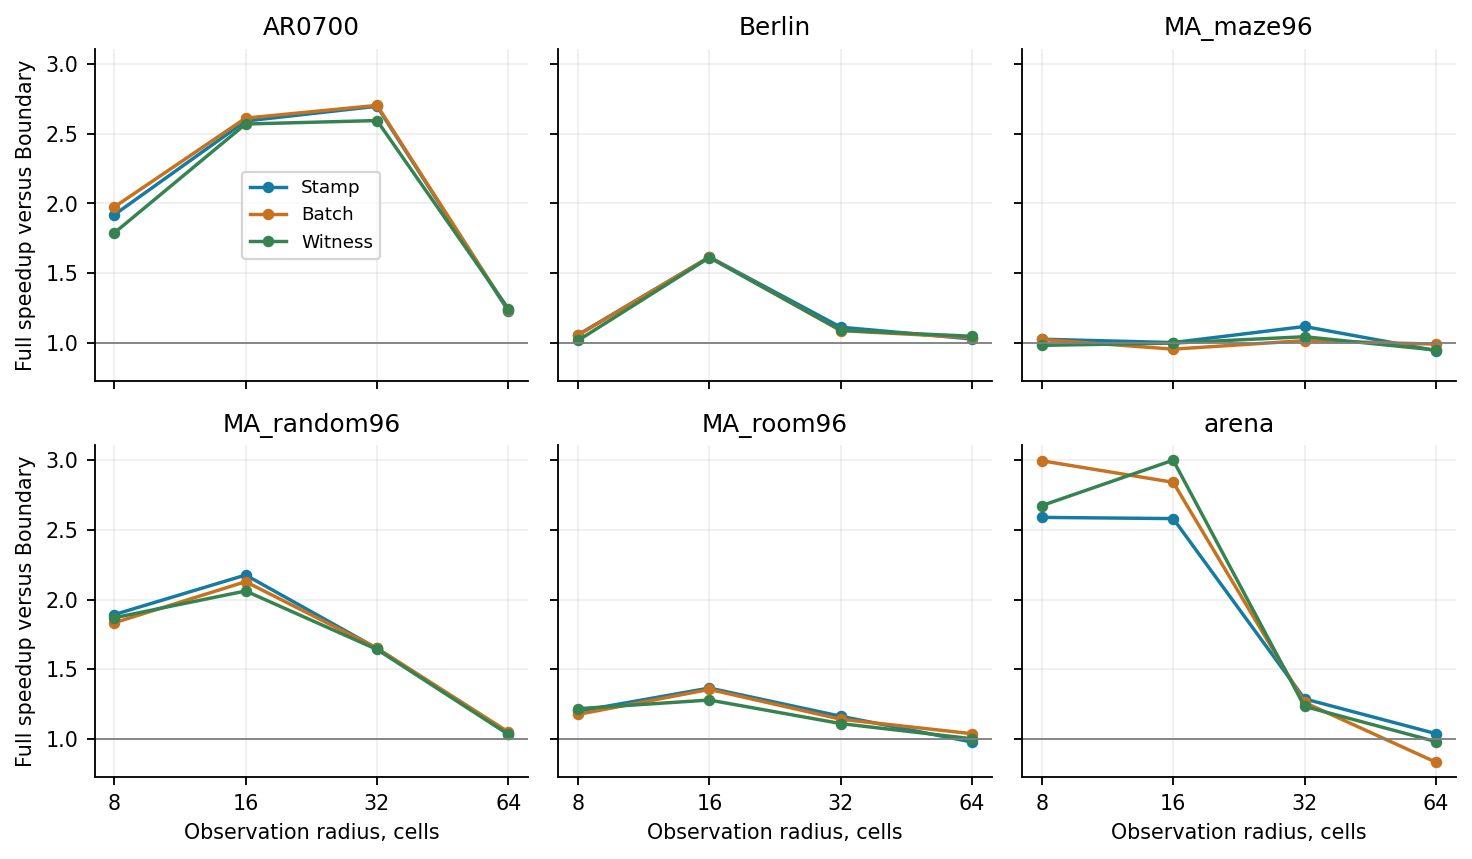

In [3]:
maps = pd.read_csv(AD/'map_pairs.csv')
display(maps[maps.cohort.eq('navigation_dynamic') & maps.baseline.eq('best_control') & maps.method.isin(new)][['control','map','method','episode_speedup','online_speedup','paired','configurations']])
display(pd.read_csv(AD/'navigation_points.csv'))
display(Image(filename=str(ROOT/'docs/mpgaa_lazy/figures/unknown_radius.png'), width=950))

## Механизмы, абляции и память

Batch против Stamp меняет выбор начального ремонта; Witness против Batch добавляет сечение. `stamp_cell` использует версии отдельных клеток; `batch_scan` всегда просматривает обученные состояния. Память получена отдельным проходом C++ allocation bytes, не RSS. Нулевые обратные уведомления при блокировках не означают нулевую работу планировщика.

,control,method,baseline,episode_speedup,online_speedup,memory_ratio,paired
141,car16,batch_mpgaa,stamp_mpgaa,1.014111,1.015321,1.000000,90
145,grid8,batch_mpgaa,stamp_mpgaa,1.003260,1.001493,1.000000,96
146,car16,witness_mpgaa,stamp_mpgaa,0.989986,0.988174,0.988247,90
150,grid8,witness_mpgaa,stamp_mpgaa,0.948225,0.953255,0.979751,96
155,car16,stamp_mpgaa,batch_mpgaa,0.986085,0.984910,1.000000,90
159,grid8,stamp_mpgaa,batch_mpgaa,0.996751,0.998509,1.000000,96
160,car16,witness_mpgaa,batch_mpgaa,0.976210,0.973263,0.988247,90
164,grid8,witness_mpgaa,batch_mpgaa,0.945144,0.951833,0.979751,96
169,car16,stamp_mpgaa,stamp_cell,0.996369,0.988572,1.133404,90
170,grid8,stamp_mpgaa,stamp_cell,0.984800,0.965507,1.137162,96


,control,family,method,edit_kind,time_s,blocks,opens,expansions,checked_cells,notify_probes,...,mask_refreshes,mask_hits,cut_checks,cut_reuses,cut_primitives,edit_batches,scan_batches,seed_tests,arrow_checks,cover_tests
0,car16,churn,batch_mpgaa,blocks,0.004350,514,0,0,2458,0,...,82,656,0,0,0,0,0,0,738,0
20,car16,churn,stamp_mpgaa,blocks,0.007982,514,0,0,2458,0,...,82,656,0,0,0,0,0,0,738,0
22,car16,churn,witness_mpgaa,blocks,0.007713,514,0,0,2404,0,...,82,656,170,166,304,0,0,0,738,2040
24,car16,history,batch_mpgaa,blocks,0.000270,32,0,0,0,0,...,0,300,0,0,0,0,0,0,300,0
44,car16,history,stamp_mpgaa,blocks,0.000298,32,0,0,0,0,...,0,300,0,0,0,0,0,0,300,0
46,car16,history,witness_mpgaa,blocks,0.000387,32,0,0,0,0,...,0,300,0,0,0,0,0,0,300,0
48,car16,off_path,batch_mpgaa,blocks,0.010550,3344,0,0,17515,0,...,579,2645,0,0,0,0,0,0,3224,0
58,car16,off_path,stamp_mpgaa,blocks,0.013158,3344,0,0,17515,0,...,579,2645,0,0,0,0,0,0,3224,0
59,car16,off_path,witness_mpgaa,blocks,0.013325,3344,0,0,17088,0,...,579,2645,1048,995,1856,0,0,0,3224,13345
60,car16,on_path,batch_mpgaa,blocks,13.876994,1156,0,2289787,45193113,0,...,1719086,573200,0,0,0,0,0,0,2499,0


median         max
control method                             
car16   batch_mpgaa    1.575817  248.940525
        stamp_mpgaa    1.575817  248.940525
        witness_mpgaa  1.594526  253.156696
grid8   batch_mpgaa    0.161522   10.632587
        stamp_mpgaa    0.161522   10.632587
        witness_mpgaa  0.165565   10.742393

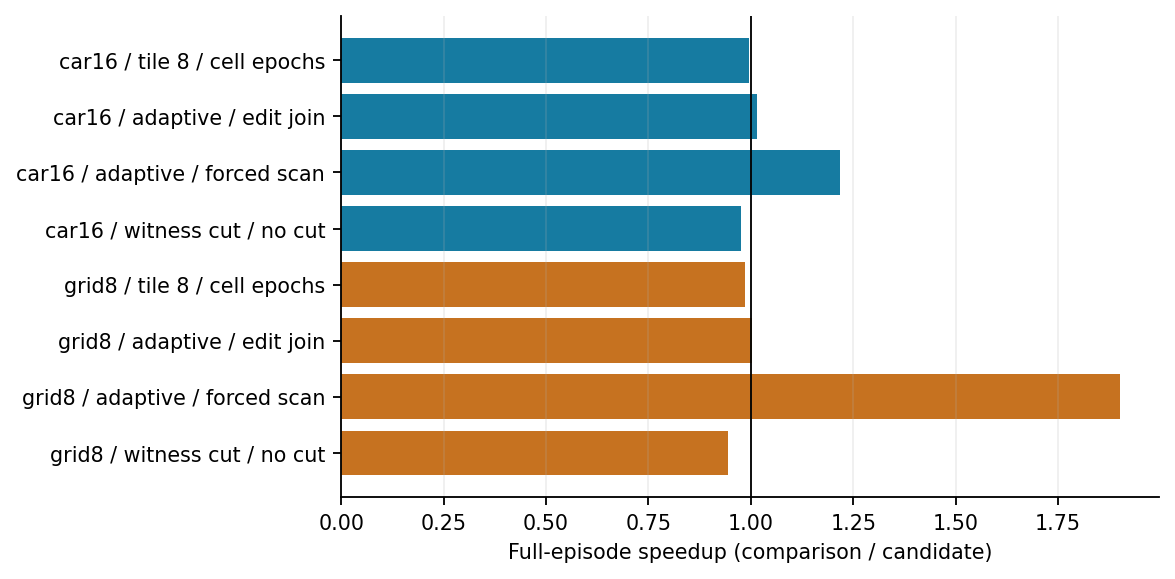

In [4]:
display(summary[summary.cohort.eq('replay') & summary.method.isin(new) & summary.baseline.isin(['stamp_cell','batch_scan','stamp_mpgaa','batch_mpgaa'])][['control','method','baseline','episode_speedup','online_speedup','memory_ratio','paired']])
display(pd.read_csv(AD/'repair_work.csv').query('method in @new and edit_kind == "blocks"'))
display(cases[cases.method.isin(new)].groupby(['control','method']).peak_heap_bytes.agg(['median','max'])/2**20)
display(Image(filename=str(ROOT/'docs/mpgaa_lazy/figures/ablations.png'), width=950))